<a href="https://colab.research.google.com/github/vasuems/ADS/blob/master/Mitre_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install mitreattack-python (uncomment if not already installed)
!pip install mitreattack-python

from mitreattack.stix20 import MitreAttackData


In [ ]:
# Cell 2: Download the MITRE ATT&CK Enterprise STIX data
# We'll use the latest STIX 2.1 data.
# This will download the file into the Colab environment.
!wget https://raw.githubusercontent.com/mitre-attack/attack-stix-data/master/enterprise-attack/enterprise-attack.json -O enterprise-attack.json

--2025-07-09 04:14:38--  https://raw.githubusercontent.com/mitre-attack/attack-stix-data/master/enterprise-attack/enterprise-attack.json
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 44879463 (43M) [text/plain]
Saving to: ‘enterprise-attack.json’

enterprise-attack.j 100%[===================>]  42.80M  96.4MB/s    in 0.4s    

2025-07-09 04:14:38 (96.4 MB/s) - ‘enterprise-attack.json’ saved [44879463/44879463]



In [ ]:
# Load ATT&CK data globally
attack_data = None

try:
    attack_data = MitreAttackData("enterprise-attack.json")
    print("ATT&CK data loaded successfully.")
except Exception as e:
    print(f"Error loading ATT&CK data: {e}")
    print("Please ensure 'enterprise-attack.json' is present in your environment.")
    exit()


ATT&CK data loaded successfully.


In [48]:
# Define your starting technique
initial_technique_id = "T1548"


In [49]:
tech_obj = attack_data.get_object_by_attack_id(initial_technique_id, "attack-pattern")
print(tech_obj)


{"type": "attack-pattern", "spec_version": "2.1", "id": "attack-pattern--67720091-eee3-4d2d-ae16-8264567f6f5b", "created_by_ref": "identity--c78cb6e5-0c4b-4611-8297-d1b8b55e40b5", "created": "2020-01-30T13:58:14.373Z", "modified": "2025-04-15T19:58:37.690Z", "name": "Abuse Elevation Control Mechanism", "description": "Adversaries may circumvent mechanisms designed to control elevate privileges to gain higher-level permissions. Most modern systems contain native elevation control mechanisms that are intended to limit privileges that a user can perform on a machine. Authorization has to be granted to specific users in order to perform tasks that can be considered of higher risk.(Citation: TechNet How UAC Works)(Citation: sudo man page 2018) An adversary can perform several methods to take advantage of built-in control mechanisms in order to escalate privileges on a system.(Citation: OSX Keydnap malware)(Citation: Fortinet Fareit)", "kill_chain_phases": [{"kill_chain_name": "mitre-attack"

In [50]:
T1548 = attack_data.get_object_by_attack_id(initial_technique_id, "attack-pattern")
#attack_data.print_stix_object(T1134, pretty=True)

In [51]:
#get attack pattern id
attack_pattern_id = T1548.id
print(attack_pattern_id)

attack-pattern--67720091-eee3-4d2d-ae16-8264567f6f5b


In [52]:
groups = attack_data.get_groups_using_technique(attack_pattern_id)
print(groups)

[]


In [ ]:
import networkx as nx

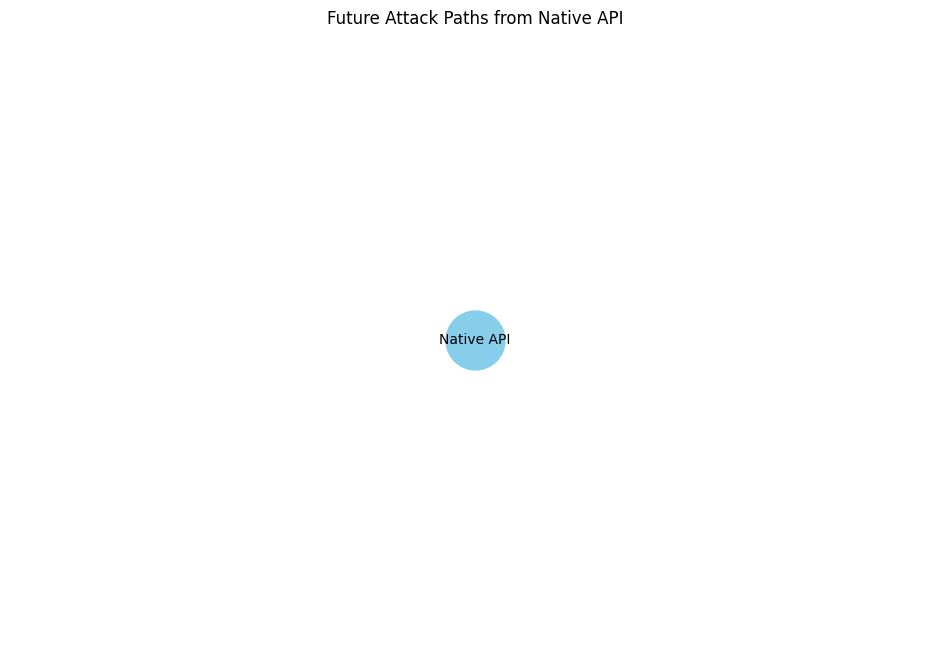

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# 1️⃣ Step: Get all group-to-technique relationships
groups = attack_data.all_groups_using_all_techniques

# 2️⃣ Print first five techniques used by each group
for group_id, rels in group_techniques.items():
    #print(f"\nGroup ID: {group_id}")
    for rel in rels[:5]:
        tech = rel.get("object")
        #if tech:
            #print(f"  Technique: {tech.name} ({tech.id})")

# 3️⃣ Define the starting technique (T1106 - Native API)
start_tid = "T1106"
start_obj = attack_data.get_object_by_attack_id(start_tid, "attack-pattern")
assert start_obj, f"Technique {start_tid} not found."
#print(f"\nUsing start technique: {start_obj.name} ({start_obj.id})")

# 4️⃣ Initialize a directed graph
G = nx.DiGraph()
G.add_node(start_obj.name)

# 5️⃣ Find groups that use the starting technique
# We loop through `group_techniques` to check which groups include T1106
for group_id, rels in group_techniques.items():
    used = False
    for rel in rels:
        tech = rel.get("object")
        if tech and tech.id == start_obj.id:
            used = True
            print(f"Group {group_id} uses {start_obj.id} ({start_obj.name})")
            break
    if not used:
        continue  # skip groups that don't use T1106

    #print(f"\n⚔️ Group `{group_id}` uses {start_obj.id}, adding connected techniques:")

    # 6️⃣ Add other techniques used by this group (excluding the start)
    for rel in rels:
        tech = rel.get("object")
        if tech and tech.id != start_obj.id:
            G.add_node(tech.name)
            G.add_edge(start_obj.name, tech.name)
            print(f"   ➤ {tech.name} ({tech.id})")

# 7️⃣ Visualize the graph
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.4, seed=42)
nx.draw_networkx(G, pos, with_labels=True, node_color='skyblue',
                 edge_color='gray', node_size=1800, font_size=10)
plt.title(f"Future Attack Paths from {start_obj.name}")
plt.axis("off")
plt.show()


In [47]:
import networkx as nx
import matplotlib.pyplot as plt

# Get all techniques
techniques = {tech.id: tech for tech in attack_data.get_techniques(remove_revoked_deprecated=True)}

# Build a graph of techniques using relationships
G = nx.DiGraph()

# Add edges for technique-to-technique relationships (via shared intrusion sets)
group_techniques = attack_data.all_groups_using_all_techniques

for group_id, rels in group_techniques.items():
    technique_ids_for_group = [rel["object"].id for rel in rels if rel.get("object") and rel["object"].id in techniques]
    for src_id in technique_ids_for_group:
        for tgt_id in technique_ids_for_group:
            if src_id != tgt_id:
                src_name = techniques[src_id].name
                tgt_name = techniques[tgt_id].name
                G.add_edge(src_name, tgt_name)


# Find start technique name using external_id "T1596.005"
start_obj = attack_data.get_object_by_attack_id("T1548", "attack-pattern")
if not start_obj:
    start_obj = attack_data.get_object_by_attack_id("T1548", "attack-pattern")
print(start_obj)
start_tech_name = start_obj.name if start_obj else None
#start_tech_id = "attack-pattern--3f18edba-28f4-4bb9-82c3-8aa60dcac5f7"#start_obj.id if start_obj else None
start_tech_id = start_obj.id if start_obj else None
print(f"start_tech_id:{start_tech_id}")
print(start_tech_name)
print(f"Start Technique: {start_obj.name} ({start_obj.id})" if start_obj else "Start Technique: Unknown")
subs_of_techs = attack_data.get_subtechniques_of_technique(start_tech_id)
print(f"Sub-techniques of {start_tech_id} ({len(subs_of_techs)}):")
for s in subs_of_techs:
        sub = s["object"]
        print(f"* {sub.name} ({attack_data.get_attack_id(sub.id)})")
# Get possible future paths (successors in the graph)
#group_sub_techniques = attack_data.get_subtechniques_using_group(start_obj.id)
#print(group_sub_techniques)
#future_paths = list(G.successors(start_tech_name)) if start_tech_name else []
#future_paths = list(G.successors(start_tech_name)) if start_tech_name and start_tech_name in G else []
##print(future_paths)
# Output
#print("Start Technique:", start_tech_name)
#print("Next Possible Techniques:")
#for tech_name in future_paths[:10]:
    #print(f"- {tech_name}")

# Optional: Visualize the graph (can be very large)
# plt.figure(figsize=(12, 8))
# pos = nx.spring_layout(G, k=0.3, seed=42)
# nx.draw_networkx(G, pos, with_labels=True, node_color='skyblue',
#                  edge_color='gray', node_size=1000, font_size=8)
# plt.title(f"Technique Relationships via Shared Groups")
# plt.axis("off")
# plt.show()

{"type": "attack-pattern", "spec_version": "2.1", "id": "attack-pattern--67720091-eee3-4d2d-ae16-8264567f6f5b", "created_by_ref": "identity--c78cb6e5-0c4b-4611-8297-d1b8b55e40b5", "created": "2020-01-30T13:58:14.373Z", "modified": "2025-04-15T19:58:37.690Z", "name": "Abuse Elevation Control Mechanism", "description": "Adversaries may circumvent mechanisms designed to control elevate privileges to gain higher-level permissions. Most modern systems contain native elevation control mechanisms that are intended to limit privileges that a user can perform on a machine. Authorization has to be granted to specific users in order to perform tasks that can be considered of higher risk.(Citation: TechNet How UAC Works)(Citation: sudo man page 2018) An adversary can perform several methods to take advantage of built-in control mechanisms in order to escalate privileges on a system.(Citation: OSX Keydnap malware)(Citation: Fortinet Fareit)", "kill_chain_phases": [{"kill_chain_name": "mitre-attack"